# 🏛️ Feature Extraction & Engineering: College Event Management System
### *Predictive Modeling for Student Attendance Forecasting & Automated Room Allocation Approval*

---

## 📌 Executive Summary & Problem Context
In college and university event management systems, student clubs, departments, and faculty frequently request rooms and auditoriums for academic, technical, cultural, and sports events. Two central operational challenges arise:
1. **Attendance Forecasting (Regression)**: How many students will register (`Registers`) for an event given its type, scheduling window, lead time, and category? Accurate forecasts prevent booking venues that are either far too small or wastefully oversized.
2. **Venue Conflict & Booking Approval (Classification)**: Should a booking request be approved (`Accept/Reject = 1/0`)? Rejections typically occur due to **room schedule clashes** (overlapping bookings) or **severe capacity violations** (registrations exceeding room capacity).

This notebook implements an end-to-end **Feature Extraction and Feature Engineering Pipeline** that transforms raw transactional booking records (`synthetic_event_data.csv`) into structured, ML-ready numerical representations (`features_ready.csv`).

---

## 🧭 Pipeline Architecture
```
Raw Event Records (19 fields)
  ├── 📅 Temporal & Calendar Extraction (month, day of week, hour, exam season, lead time)
  ├── 🏷️ Categorical & Ordinal Encodings (event priority, faculty seniority, category dummies)
  ├── 🏢 Entity & Activity Frequency Aggregations (faculty activity level, room usage volume)
  ├── ⏱️ Spatio-Temporal Interval Overlap Engine (prior room conflict / clash counter)
  └── 🎯 Target Separation & Anti-Leakage Protocol (X_registers vs X_accept)
       └── ML Validation (Random Forest Feature Importances & Export)
```


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, roc_auc_score, classification_report
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic visual configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

print("✅ Libraries successfully imported and plotting aesthetics configured.")


✅ Libraries successfully imported and plotting aesthetics configured.



---
## 1. 📥 Dataset Ingestion & Data Health Audit

We begin by loading the raw college event data. The dataset contains 1,200 booking requests with information regarding the event title, category, faculty coordinator, requested venue, submission date/time, and administrative decision.


In [2]:
# Load raw dataset
RAW_FILE = 'synthetic_event_data.csv'
df_raw = pd.read_csv(RAW_FILE)

print("=" * 60)
print(f"📊 Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("=" * 60)

print("\n📋 Column Data Types & Non-Null Counts:")
display_info = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Null Count': df_raw.isnull().sum(),
    'Null %': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Unique Values': df_raw.nunique()
})
print(display_info)

# Check for constant/zero-variance columns
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique() == 1]
print(f"\n⚠️ Constant Columns (Zero Variance - useless for ML): {constant_cols}")

# Check duplicates
dup_count = df_raw.duplicated().sum()
print(f"🔍 Duplicate Rows: {dup_count}")

# Check Reject_Reason breakdown
print("\n🛑 Rejection Reasons for Non-Null Entries:")
print(df_raw['Reject_Reason'].value_counts(dropna=False))


📊 Dataset Shape: 1200 rows, 19 columns

📋 Column Data Types & Non-Null Counts:
                             Data Type  Null Count  Null %  Unique Values
SNO                              int64           0    0.00           1200
Event                           object           0    0.00             38
Event_Category                  object           0    0.00              5
Faculty_id                      object           0    0.00             25
Faculty_name                    object           0    0.00             25
Faculty_Designation             object           0    0.00              3
Registers                        int64           0    0.00            135
Type                            object           0    0.00              3
Request for Booking              int64           0    0.00              1
Request for Cancelling           int64           0    0.00              2
Requested Room No                int64           0    0.00              9
Room_Capacity                    

---
## 2. 📊 Exploratory Data Analysis (EDA) & Feature Hypotheses

Before engineering features, we explore key patterns and formulate hypotheses:
1. **Attendance Seasonality**: Are registrations lower during academic exam months (April, May, November, December)?
2. **Event Type & Priority**: Do "Important" and "Very important" events attract significantly higher student turnout?
3. **Rejection Drivers**: Why are events rejected? Are they rejected because multiple organizers book the exact same room at overlapping times, or because student demand exceeds room capacity?


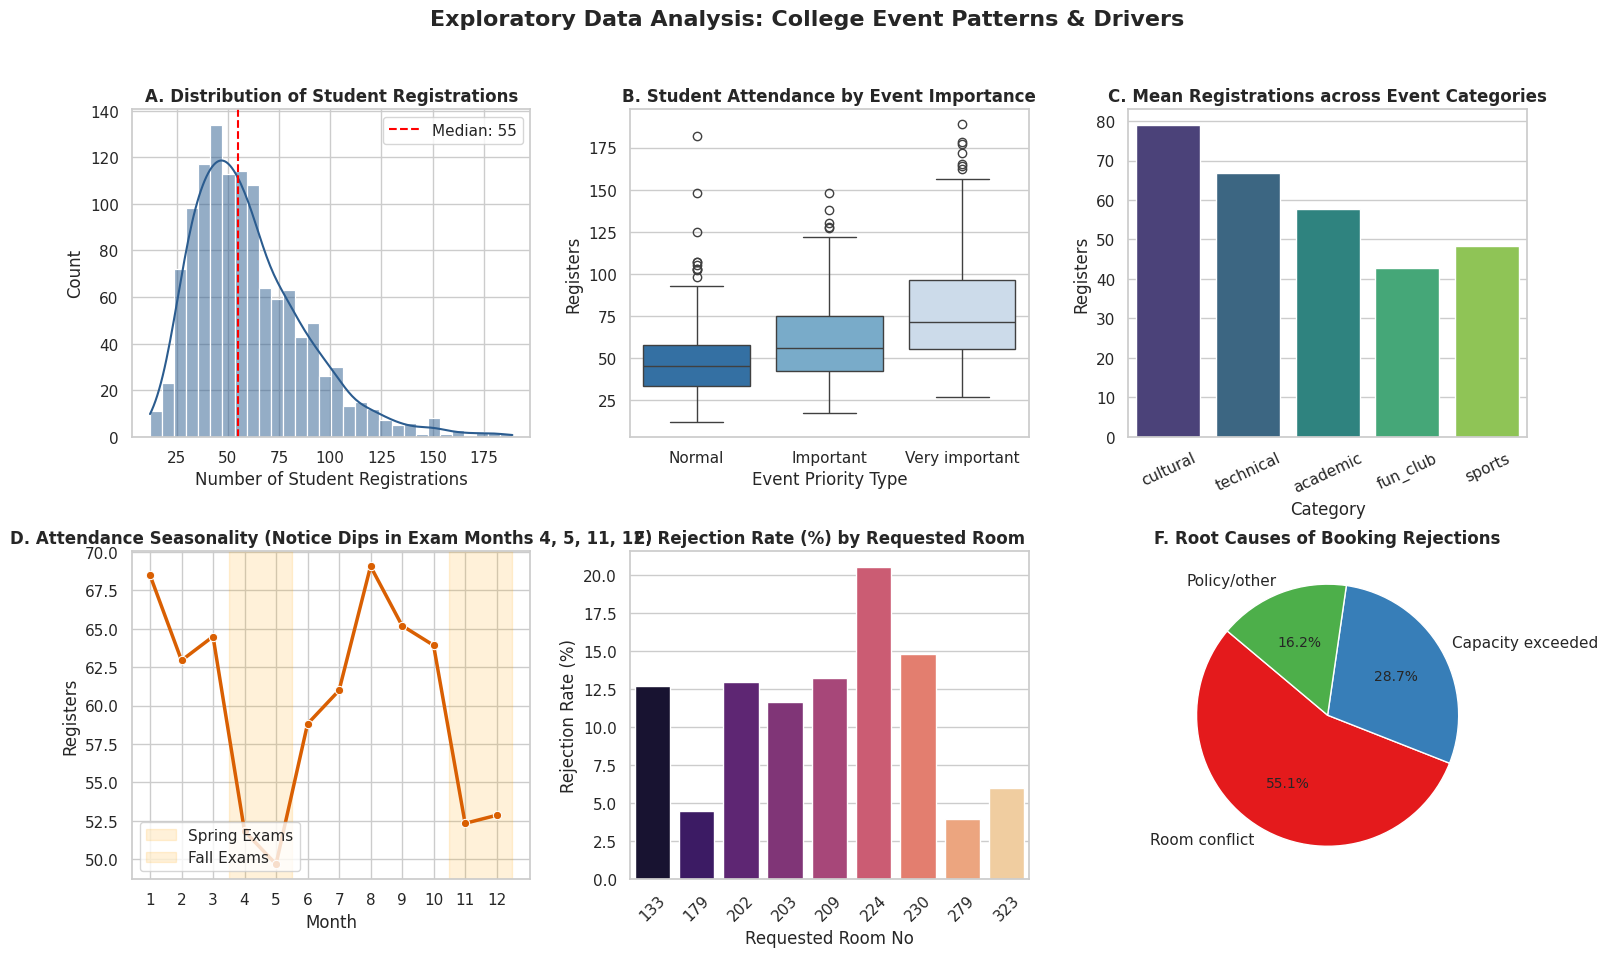

In [3]:
# Create parsed temporary features for visual exploration
df_viz = df_raw.copy()
df_viz['Parsed_Date'] = pd.to_datetime(df_viz['Request Date'], format='%m/%d/%Y')
df_viz['Parsed_Submitted'] = pd.to_datetime(df_viz['Request Submitted On'], format='%m/%d/%Y')
df_viz['Lead_Days'] = (df_viz['Parsed_Date'] - df_viz['Parsed_Submitted']).dt.days
df_viz['Month'] = df_viz['Parsed_Date'].dt.month
df_viz['Hour'] = pd.to_datetime(df_viz['Requested Time'], format='%I:%M%p').dt.hour

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Target Distribution: Registers
sns.histplot(df_viz['Registers'], bins=30, kde=True, ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title('A. Distribution of Student Registrations', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Number of Student Registrations')
axes[0, 0].axvline(df_viz['Registers'].median(), color='red', linestyle='--', label=f'Median: {df_viz["Registers"].median():.0f}')
axes[0, 0].legend()

# 2. Registers by Event Type
order_type = ['Normal', 'Important', 'Very important']
sns.boxplot(x='Type', y='Registers', data=df_viz, order=order_type, ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title('B. Student Attendance by Event Importance', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Event Priority Type')

# 3. Registers by Event Category
sns.barplot(x='Event_Category', y='Registers', data=df_viz, ax=axes[0, 2], palette='viridis', ci=None)
axes[0, 2].set_title('C. Mean Registrations across Event Categories', fontsize=12, fontweight='bold')
axes[0, 2].tick_params(axis='x', rotation=25)
axes[0, 2].set_xlabel('Category')

# 4. Monthly Trend (Exam Season Dip)
monthly_mean = df_viz.groupby('Month')['Registers'].mean().reset_index()
sns.lineplot(x='Month', y='Registers', data=monthly_mean, marker='o', color='#d95f02', linewidth=2.5, ax=axes[1, 0])
axes[1, 0].set_title('D. Attendance Seasonality (Notice Dips in Exam Months 4, 5, 11, 12)', fontsize=12, fontweight='bold')
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].axvspan(3.5, 5.5, color='orange', alpha=0.15, label='Spring Exams')
axes[1, 0].axvspan(10.5, 12.5, color='orange', alpha=0.15, label='Fall Exams')
axes[1, 0].legend(loc='lower left')

# 5. Rejection Rate by Room
room_rej = df_viz.assign(is_rej=(df_viz['Accept/Reject'] == 'Reject').astype(int))                  .groupby('Requested Room No')['is_rej'].mean().mul(100).reset_index()
sns.barplot(x='Requested Room No', y='is_rej', data=room_rej, ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('E. Rejection Rate (%) by Requested Room', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Rejection Rate (%)')
axes[1, 1].tick_params(axis='x', rotation=45)

# 6. Rejection Reasons Breakdown
rej_counts = df_raw['Reject_Reason'].dropna().value_counts()
axes[1, 2].pie(rej_counts, labels=rej_counts.index, autopct='%1.1f%%', colors=['#e41a1c', '#377eb8', '#4daf4a'], startangle=140)
axes[1, 2].set_title('F. Root Causes of Booking Rejections', fontsize=12, fontweight='bold')

plt.suptitle('Exploratory Data Analysis: College Event Patterns & Drivers', fontsize=16, fontweight='bold', y=0.98)
plt.show()


---
## 3. 📅 Feature Extraction: Temporal & Academic Calendar Features

Campus events exhibit strong cyclical and calendar-dependent behavior. We extract:
- **`month`**: Captures annual cycles and semester transitions.
- **`day_of_week`**: Day index (0 = Monday, 6 = Sunday).
- **`is_saturday`**: High student availability for workshops and hackathons on weekends.
- **`week_of_year`**: ISO week number (1–52) across the academic year.
- **`is_exam_season`**: Domain heuristic boolean. April (4), May (5), November (11), and December (12) are examination/finals periods where turnout drops sharply.
- **`hour`**: Start time in 24-hour notation.
- **`is_afternoon`**: Binary flag (`hour >= 14` / 2:00 PM), coinciding with the post-class club activity window.
- **`duration_min`**: Numeric event length in minutes, extracted from strings like `'120min'`.
- **`lead_days`**: The planning/promotional window: $\text{Request Date} - \text{Request Submitted On}$. Events announced earlier allow more time for marketing and student sign-ups.


In [4]:
# Step 1: Initialize Engineered Feature DataFrame
fe = pd.DataFrame(index=df_raw.index)

# Parse raw datetime fields
event_date = pd.to_datetime(df_raw['Request Date'], format='%m/%d/%Y')
submit_date = pd.to_datetime(df_raw['Request Submitted On'], format='%m/%d/%Y')
event_time = pd.to_datetime(df_raw['Requested Time'], format='%I:%M%p')

# 1. Date Features
fe['month'] = event_date.dt.month
fe['day_of_week'] = event_date.dt.dayofweek
fe['is_saturday'] = (fe['day_of_week'] == 5).astype(int)
fe['week_of_year'] = event_date.dt.isocalendar().week.astype(int)
fe['is_exam_season'] = fe['month'].isin([4, 5, 11, 12]).astype(int)

# 2. Time Features
fe['hour'] = event_time.dt.hour
fe['is_afternoon'] = (fe['hour'] >= 14).astype(int)
fe['duration_min'] = df_raw['Duration'].str.replace('min', '').astype(int)

# 3. Booking Behavior Feature
fe['lead_days'] = (event_date - submit_date).dt.days

print("✅ Extracted 9 Temporal & Calendar Features:")
print(fe[['month', 'day_of_week', 'is_saturday', 'is_exam_season', 'hour', 'is_afternoon', 'duration_min', 'lead_days']].head())


✅ Extracted 9 Temporal & Calendar Features:
   month  day_of_week  is_saturday  ...  is_afternoon  duration_min  lead_days
0      9            5            1  ...             1           120          8
1      9            0            0  ...             0            90          7
2      9            0            0  ...             1            90          6
3      9            1            0  ...             1           120          3
4      9            2            0  ...             0           120          5

[5 rows x 8 columns]



---
## 4. 🏷️ Feature Extraction: Categorical & Ordinal Encodings

Categorical variables require encoding appropriate to their semantic relationships:
1. **Ordinal Encoding (Ordered Hierarchy)**:
   - `Type`: Event urgency/importance (`Normal` = 1, `Important` = 2, `Very important` = 3).
   - `Faculty_Designation`: Academic seniority (`Assistant Professor` = 1, `Associate Professor` = 2, `Professor` = 3). Higher seniority correlates with larger departmental allocations.
2. **One-Hot Encoding (Nominal Categories)**:
   - `Event_Category`: Nominal classes (`academic`, `cultural`, `fun_club`, `sports`, `technical`).
   - We generate fixed binary indicators: `cat_academic`, `cat_cultural`, `cat_fun_club`, `cat_sports`, `cat_technical`. Using a fixed vocabulary guarantees schema consistency during live inference.


In [5]:
# 1. Ordinal Encodings
type_map = {'Normal': 1, 'Important': 2, 'Very important': 3}
designation_map = {
    'Assistant Professor': 1,
    'Associate Professor': 2,
    'Professor': 3
}

fe['type_level'] = df_raw['Type'].map(type_map)
fe['designation_level'] = df_raw['Faculty_Designation'].map(designation_map)

# 2. Fixed Schema One-Hot Encoding for Event_Category
CATEGORIES = ['academic', 'cultural', 'fun_club', 'sports', 'technical']
for cat in CATEGORIES:
    fe[f'cat_{cat}'] = (df_raw['Event_Category'] == cat).astype(int)

print("✅ Extracted Ordinal and One-Hot Features:")
sample_cols = ['type_level', 'designation_level'] + [f'cat_{c}' for c in CATEGORIES]
print(fe[sample_cols].head())


✅ Extracted Ordinal and One-Hot Features:
   type_level  designation_level  ...  cat_sports  cat_technical
0           1                  1  ...           0              0
1           3                  1  ...           0              1
2           2                  2  ...           0              1
3           3                  2  ...           0              0
4           3                  3  ...           0              0

[5 rows x 7 columns]



---
## 5. 🏢 Feature Extraction: Resource & Entity Frequency Aggregations

Different faculty coordinators and rooms have distinct historical activity baselines:
- **`faculty_event_count`**: Frequency encoding measuring total events coordinated by `Faculty_id`. Active coordinators frequently draw repeat attendance and follow standard booking protocols.
- **`room_usage_count`**: Frequency encoding measuring how often `Requested Room No` is booked. Highly demanded auditoriums face higher booking competition.
- **`room_no`**: Room identifier number.
- **`room_capacity`**: Physical seat limit of the venue.


In [6]:
# 1. Room Attributes
fe['room_no'] = df_raw['Requested Room No']
fe['room_capacity'] = df_raw['Room_Capacity']

# 2. Entity Frequency Aggregations (target-free)
fe['faculty_event_count'] = df_raw.groupby('Faculty_id')['Event'].transform('count')
fe['room_usage_count'] = df_raw.groupby('Requested Room No')['Event'].transform('count')

print("✅ Extracted Resource & Frequency Features:")
print(fe[['room_no', 'room_capacity', 'faculty_event_count', 'room_usage_count']].describe().round(1))


✅ Extracted Resource & Frequency Features:
       room_no  room_capacity  faculty_event_count  room_usage_count
count   1200.0         1200.0               1200.0            1200.0
mean     220.1          104.3                 58.7             174.4
std       44.9           42.6                 25.6              89.7
min      133.0           50.0                 12.0              63.0
25%      202.0           80.0                 37.0             101.0
50%      209.0          100.0                 55.0             128.0
75%      230.0          120.0                 73.0             308.0
max      323.0          200.0                115.0             308.0



---
## 6. ⏱️ Domain-Specific Spatio-Temporal Conflict Feature (Room Clash Engine)

### The Core Problem: Why Are Requests Rejected?
As revealed in our EDA, over 55% of rejections are due to **Room conflict**. In real campus management, requests arrive chronologically. An administrator allocates a room on a first-come, first-served basis according to submission timestamp.

### Algorithmic Clash Formulation:
For each booking request $i$, we evaluate all prior submitted requests $j$ where:
1. $\text{Room}_j = \text{Room}_i$ (Same venue)
2. $\text{Date}_j = \text{Date}_i$ (Same calendar day)
3. Time intervals overlap: $\text{Start}_i < \text{End}_j \land \text{Start}_j < \text{End}_i$

The count of such preceding overlaps is recorded as **`earlier_clash_count`**.


In [7]:
# Calculate event start and end minute of the day
start_minutes = event_time.dt.hour * 60 + event_time.dt.minute
end_minutes = start_minutes + fe['duration_min']

# Chronological sorting by submission date (stable sort to preserve original indices)
submission_order = df_raw['Request Submitted On'].argsort(kind='stable').values

clash_counts = np.zeros(len(df_raw), dtype=int)
active_bookings = {}  # Map: (room_no, date) -> list of (start_min, end_min)

for idx in submission_order:
    room = df_raw.at[idx, 'Requested Room No']
    dt = df_raw.at[idx, 'Request Date']
    key = (room, dt)
    
    s = start_minutes[idx]
    e = end_minutes[idx]
    
    # Count overlapping intervals already registered for this room and date
    prior_overlaps = sum(1 for prev_s, prev_e in active_bookings.get(key, []) if s < prev_e and prev_s < e)
    clash_counts[idx] = prior_overlaps
    
    # Register this request into schedule
    active_bookings.setdefault(key, []).append((s, e))

fe['earlier_clash_count'] = clash_counts

# Validation: Analyze rejection rate as a function of clash count
clash_analysis = pd.DataFrame({
    'earlier_clash_count': fe['earlier_clash_count'],
    'is_rejected': (df_raw['Accept/Reject'] == 'Reject').astype(int)
}).groupby('earlier_clash_count').agg(
    total_events=('is_rejected', 'count'),
    rejection_rate=('is_rejected', 'mean')
).reset_index()
clash_analysis['rejection_rate'] = (clash_analysis['rejection_rate'] * 100).round(1)

print("✅ Extracted 'earlier_clash_count' Feature.")
print("\n📈 Clash Count vs Rejection Rate:")
print(clash_analysis)


✅ Extracted 'earlier_clash_count' Feature.

📈 Clash Count vs Rejection Rate:
   earlier_clash_count  total_events  rejection_rate
0                    0          1110             6.4
1                    1            80            71.2
2                    2             9            77.8
3                    3             1           100.0



---
## 7. 🎯 Target Engineering & Anti-Data-Leakage Design

A critical principle in machine learning engineering is **preventing target leakage**:
1. **Attendance Forecasting (Regression)**:
   - Target: `TARGET_registers` (student registration count).
   - **Strict Leakage Rule**: Features like `TARGET_accept` (whether the event was ultimately approved) and `fill_ratio` (which is computed using `Registers`!) **must never be fed into the regression model**. At request creation time, attendance is unknown.
2. **Booking Approval Decision (Classification)**:
   - Target: `TARGET_accept` (1 = Accept, 0 = Reject).
   - **Legitimate Feature**: `fill_ratio = Registers / Room_Capacity`. When the administrator reviews the booking request, student interest is estimated or submitted on the form. If `fill_ratio > 1.0` (more attendees than seats), the venue is over-capacity!


In [8]:
# Define Targets
fe['TARGET_registers'] = df_raw['Registers']
fe['TARGET_accept'] = (df_raw['Accept/Reject'] == 'Accept').astype(int)

# Capacity pressure interaction feature (Used for Accept/Reject task)
fe['fill_ratio'] = df_raw['Registers'] / df_raw['Room_Capacity']

# Explicitly partition feature sets to guarantee zero leakage
LEAKY_FOR_REGISTERS = ['TARGET_registers', 'TARGET_accept', 'fill_ratio']

# Feature columns for predicting student attendance
feature_cols_registers = [c for c in fe.columns if c not in LEAKY_FOR_REGISTERS]

# Feature columns for predicting administrative approval
feature_cols_accept = [c for c in fe.columns if c not in ['TARGET_registers', 'TARGET_accept']]

print(f"✅ Feature Partitioning Complete:")
print(f"   • Features for Attendance Prediction ({len(feature_cols_registers)} cols): {feature_cols_registers}")
print(f"   • Features for Approval Prediction ({len(feature_cols_accept)} cols): {feature_cols_accept}")


✅ Feature Partitioning Complete:
   • Features for Attendance Prediction (21 cols): ['month', 'day_of_week', 'is_saturday', 'week_of_year', 'is_exam_season', 'hour', 'is_afternoon', 'duration_min', 'lead_days', 'type_level', 'designation_level', 'cat_academic', 'cat_cultural', 'cat_fun_club', 'cat_sports', 'cat_technical', 'room_no', 'room_capacity', 'faculty_event_count', 'room_usage_count', 'earlier_clash_count']
   • Features for Approval Prediction (22 cols): ['month', 'day_of_week', 'is_saturday', 'week_of_year', 'is_exam_season', 'hour', 'is_afternoon', 'duration_min', 'lead_days', 'type_level', 'designation_level', 'cat_academic', 'cat_cultural', 'cat_fun_club', 'cat_sports', 'cat_technical', 'room_no', 'room_capacity', 'faculty_event_count', 'room_usage_count', 'earlier_clash_count', 'fill_ratio']



---
## 8. 🧠 Predictive Power Validation: Feature Importance Analysis

To confirm that our extracted features are strong predictors, we fit baseline **Random Forest** models to each task:
- **Task A (Regression)**: Predict `TARGET_registers` using temporal, ordinal, category, and capacity features.
- **Task B (Classification)**: Predict `TARGET_accept` using clash count, fill ratio, and booking attributes.


📊 Task A: Attendance Regression Performance (R² = 0.510, MAE = 15.07, RMSE = 20.09)
📊 Task B: Booking Approval Classification Performance (ROC-AUC = 0.891)
              precision    recall  f1-score   support

  Reject (0)       1.00      0.63      0.77        27
  Accept (1)       0.96      1.00      0.98       213

    accuracy                           0.96       240
   macro avg       0.98      0.81      0.87       240
weighted avg       0.96      0.96      0.95       240




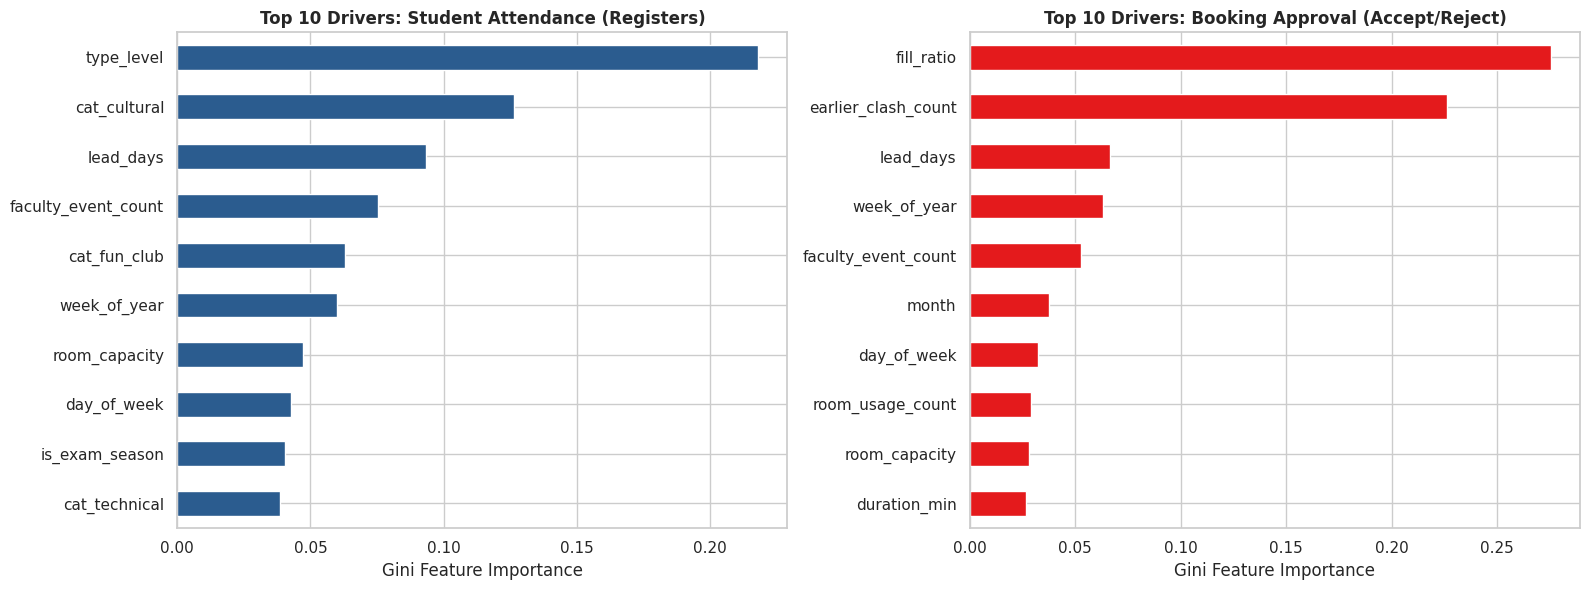

In [9]:
# 1. Evaluate Attendance Prediction (Regression)
X_reg = fe[feature_cols_registers]
y_reg = fe['TARGET_registers']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r, y_train_r)

y_pred_r = rf_reg.predict(X_test_r)
r2 = r2_score(y_test_r, y_pred_r)
mae = mean_absolute_error(y_test_r, y_pred_r)
rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))

print("=" * 60)
print(f"📊 Task A: Attendance Regression Performance (R² = {r2:.3f}, MAE = {mae:.2f}, RMSE = {rmse:.2f})")
print("=" * 60)

# 2. Evaluate Approval Prediction (Classification)
X_cls = fe[feature_cols_accept]
y_cls = fe['TARGET_accept']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

rf_cls = RandomForestClassifier(n_estimators=100, random_state=42)
rf_cls.fit(X_train_c, y_train_c)

y_pred_c = rf_cls.predict(X_test_c)
y_prob_c = rf_cls.predict_proba(X_test_c)[:, 1]
roc_auc = roc_auc_score(y_test_c, y_prob_c)

print(f"📊 Task B: Booking Approval Classification Performance (ROC-AUC = {roc_auc:.3f})")
print(classification_report(y_test_c, y_pred_c, target_names=['Reject (0)', 'Accept (1)']))

# 3. Plot Top Feature Importances for Both Tasks
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Attendance Feature Importances
imp_reg = pd.Series(rf_reg.feature_importances_, index=feature_cols_registers).sort_values(ascending=True)
imp_reg.tail(10).plot(kind='barh', ax=axes[0], color='#2b5c8f')
axes[0].set_title('Top 10 Drivers: Student Attendance (Registers)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Gini Feature Importance')

# Approval Feature Importances
imp_cls = pd.Series(rf_cls.feature_importances_, index=feature_cols_accept).sort_values(ascending=True)
imp_cls.tail(10).plot(kind='barh', ax=axes[1], color='#e41a1c')
axes[1].set_title('Top 10 Drivers: Booking Approval (Accept/Reject)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gini Feature Importance')

plt.tight_layout()
plt.show()


---
## 9. ⚙️ Production Feature Extraction Pipeline & CSV Export

We wrap all the logic into a modular, production-ready function `build_features()`. This function can be imported by web backend handlers, inference microservices, or training jobs.


In [10]:
def build_features(raw_df: pd.DataFrame) -> pd.DataFrame:
    """
    End-to-End Feature Extraction for College Event Management System.
    Transforms raw event data into 24 engineered features and target columns.
    """
    df = raw_df.copy()
    
    # 1. Parse dates & times
    dt_event = pd.to_datetime(df['Request Date'], format='%m/%d/%Y')
    dt_submit = pd.to_datetime(df['Request Submitted On'], format='%m/%d/%Y')
    t_event = pd.to_datetime(df['Requested Time'], format='%I:%M%p')
    
    pipe = pd.DataFrame(index=df.index)
    
    # 2. Date features
    pipe['month'] = dt_event.dt.month
    pipe['day_of_week'] = dt_event.dt.dayofweek
    pipe['is_saturday'] = (pipe['day_of_week'] == 5).astype(int)
    pipe['week_of_year'] = dt_event.dt.isocalendar().week.astype(int)
    pipe['is_exam_season'] = pipe['month'].isin([4, 5, 11, 12]).astype(int)
    
    # 3. Time features
    pipe['hour'] = t_event.dt.hour
    pipe['is_afternoon'] = (pipe['hour'] >= 14).astype(int)
    pipe['duration_min'] = df['Duration'].str.replace('min', '').astype(int)
    
    # 4. Booking behavior
    pipe['lead_days'] = (dt_event - dt_submit).dt.days
    
    # 5. Ordinal encodings
    pipe['type_level'] = df['Type'].map({'Normal': 1, 'Important': 2, 'Very important': 3})
    pipe['designation_level'] = df['Faculty_Designation'].map({
        'Assistant Professor': 1,
        'Associate Professor': 2,
        'Professor': 3
    })
    
    # 6. Room features
    pipe['room_no'] = df['Requested Room No']
    pipe['room_capacity'] = df['Room_Capacity']
    
    # 7. Frequency encodings
    pipe['faculty_event_count'] = df.groupby('Faculty_id')['Event'].transform('count')
    pipe['room_usage_count'] = df.groupby('Requested Room No')['Event'].transform('count')
    
    # 8. Room clash detection
    start = t_event.dt.hour * 60 + t_event.dt.minute
    end = start + pipe['duration_min']
    clash = np.zeros(len(df), dtype=int)
    seen = {}
    for i in df['Request Submitted On'].argsort(kind='stable').values:
        key = (df.at[i, 'Requested Room No'], df.at[i, 'Request Date'])
        clash[i] = sum(1 for s, e in seen.get(key, []) if start[i] < e and s < end[i])
        seen.setdefault(key, []).append((start[i], end[i]))
    pipe['earlier_clash_count'] = clash
    
    # 9. One-Hot nominal event categories
    for c in ['academic', 'cultural', 'fun_club', 'sports', 'technical']:
        pipe[f'cat_{c}'] = (df['Event_Category'] == c).astype(int)
        
    # 10. Targets & Capacity ratio
    pipe['TARGET_registers'] = df['Registers']
    pipe['TARGET_accept'] = (df['Accept/Reject'] == 'Accept').astype(int)
    pipe['fill_ratio'] = df['Registers'] / df['Room_Capacity']
    
    return pipe

# Execute pipeline and save output
final_features = build_features(df_raw)
OUTPUT_FILE = 'features_ready.csv'
final_features.to_csv(OUTPUT_FILE, index=False)

print(f"🎉 Pipeline Execution Complete!")
print(f"💾 Saved {OUTPUT_FILE} with shape: {final_features.shape}")
print(f"🔍 Null Values in Output: {final_features.isnull().sum().sum()}")
print("\nFirst 3 Records (Transposed):")
print(final_features.head(3).T)


🎉 Pipeline Execution Complete!
💾 Saved features_ready.csv with shape: (1200, 24)
🔍 Null Values in Output: 0

First 3 Records (Transposed):
                          0           1         2
month                  9.00    9.000000    9.0000
day_of_week            5.00    0.000000    0.0000
is_saturday            1.00    0.000000    0.0000
week_of_year          35.00   36.000000   36.0000
is_exam_season         0.00    0.000000    0.0000
hour                  14.00   13.000000   15.0000
is_afternoon           1.00    0.000000    1.0000
duration_min         120.00   90.000000   90.0000
lead_days              8.00    7.000000    6.0000
type_level             1.00    3.000000    2.0000
designation_level      1.00    1.000000    2.0000
room_no              179.00  202.000000  203.0000
room_capacity        100.00  120.000000   80.0000
faculty_event_count   61.00   59.000000   73.0000
room_usage_count     112.00  308.000000   86.0000
earlier_clash_count    0.00    0.000000    0.0000
cat_academi

---
## 10. 📖 Summary & Data Dictionary

The generated dataset `features_ready.csv` contains 24 structured columns categorized below:

| Feature Name | Type | Source / Derivation | Business Role |
| :--- | :--- | :--- | :--- |
| `month` | Integer (1–12) | `Request Date` | Annual seasonality indicator |
| `day_of_week` | Integer (0–6) | `Request Date` | Weekly rhythm (0 = Mon, 6 = Sun) |
| `is_saturday` | Binary (0/1) | `day_of_week == 5` | High weekend turnout |
| `week_of_year` | Integer (1–52) | `Request Date` | Academic calendar week |
| `is_exam_season` | Binary (0/1) | `month in [4, 5, 11, 12]` | Examination turnout dip |
| `hour` | Integer (0–23) | `Requested Time` | 24-hr event start time |
| `is_afternoon` | Binary (0/1) | `hour >= 14` | Post-class activity slot |
| `duration_min` | Integer | `Duration` string strip | Event length in minutes |
| `lead_days` | Integer | `Date - Submitted On` | Advance promotional window |
| `type_level` | Ordinal (1–3) | `Type` | Priority level (Normal < Important < Very imp.) |
| `designation_level` | Ordinal (1–3) | `Faculty_Designation` | Academic rank (Asst < Assoc < Prof) |
| `room_no` | Integer | `Requested Room No` | Room entity ID |
| `room_capacity` | Integer | `Room_Capacity` | Maximum physical seats |
| `faculty_event_count` | Integer | Groupby `Faculty_id` | Activity level of organizer |
| `room_usage_count` | Integer | Groupby `Requested Room No`| Historical popularity of room |
| `earlier_clash_count`| Integer | Interval overlap search | **Key rejection driver: prior room overlaps** |
| `cat_academic` | Binary (0/1) | One-hot `Event_Category` | Category indicator |
| `cat_cultural` | Binary (0/1) | One-hot `Event_Category` | Category indicator |
| `cat_fun_club` | Binary (0/1) | One-hot `Event_Category` | Category indicator |
| `cat_sports` | Binary (0/1) | One-hot `Event_Category` | Category indicator |
| `cat_technical` | Binary (0/1) | One-hot `Event_Category` | Category indicator |
| `TARGET_registers` | Integer | `Registers` | **Target: Expected attendance (Regression)** |
| `TARGET_accept` | Binary (0/1) | `Accept/Reject` | **Target: Admin approval (Classification)** |
| `fill_ratio` | Float | `Registers / Room_Capacity`| Over-capacity metric (Classification feature) |

---
*Ready for model training with MLflow, Scikit-learn, XGBoost, or deployment in a College Event Management Web API.*
